In [1]:
import pandas as pd
import numpy as np
import pickle
import SimpleITK as sitk
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions
import torch
import torch.nn as nn
import torch.optim as optim
import random
from tqdm import tqdm
import torch.nn.functional as F
from torch.optim import lr_scheduler
import time
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
device = torch.device("cuda:0")

In [2]:
import numpy as np
import pandas as pd

df_layers = pd.read_excel(
    '../../SEU_net_wo_corticalLayers.xlsx',
    header=1,
    index_col=1
)
df_layers = df_layers.iloc[:, 1:].astype(float)

seed = 12
rng = np.random.default_rng(seed)

values = df_layers.to_numpy()
n = values.shape[0]

random_matrix = rng.random((n, n))
np.fill_diagonal(random_matrix, 0)

df_random = pd.DataFrame(
    random_matrix,
    index=df_layers.index,
    columns=df_layers.columns
)

In [3]:
df_layers = df_random

## 1. Stage1

In [4]:
with open('../../brain_region_wo_layer_stage1.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999854, 0.99999971,
         1.        ]),
  'spike_voltages': array([0.00026798, 0.00013078, 0.0001027 , ..., 0.00013102, 0.00018679,
         0.00014846])},
 'LGd': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([0.0001613 , 0.0001284 , 0.00018691, ..., 0.00011591, 0.00022138,
         0.00010917])},
 'CEA': {'spike_times': array([0.00000000e+00, 1.35276967e-06, 1.55804080e-06, ...,
         9.99996026e-01, 9.99997624e-01, 1.00000000e+00]),
  'spike_voltages': array([3.35663608e-05, 6.50536604e-05, 1.05790488e-04, ...,
         6.90313609e-05, 6.91710375e-05, 5.53253303e-05])},
 'VPM': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([7.28509549e-05, 1.54141395e-04, 1.58252820e-04, ...,
         2.98089057e-04, 3.47912486e-04, 2.16961940e-04])},
 'CA3': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999981, 1.        ,
       

In [5]:
len(C_traces)

89

In [6]:
keys = list(C_traces.keys())

df_filtered = df_layers.loc[df_layers.index.intersection(keys), df_layers.columns.intersection(keys)]
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_filtered),
    index=df_filtered.index,
    columns=df_filtered.columns
)
df_scaled

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,LD,MD,SMT,PVT,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.954113,0.191792,0.180823,0.353484,0.232193,0.673980,0.115233,0.900883,0.875583,...,0.188984,0.079446,0.690112,0.314015,0.081929,0.875891,0.706758,0.786800,0.616742,0.460994
MOp,0.193971,0.000000,0.147342,0.525795,0.122681,0.109171,0.700428,0.889973,0.463513,0.810751,...,0.654157,0.709698,0.220119,0.299188,0.567442,0.371279,0.132246,0.290728,0.248528,0.993916
MOs,0.613367,0.482363,0.000000,0.580909,0.991149,0.387664,0.057497,0.184804,0.007535,0.205822,...,0.286158,0.243262,0.987262,0.490797,0.937207,0.725128,0.758611,0.809109,0.848878,0.687600
SSp-n,1.000000,0.796985,0.838361,0.000000,0.046903,0.996911,0.768440,0.084812,0.724682,0.723203,...,0.966211,0.782928,0.056364,0.633646,0.391451,0.969072,0.278329,0.104051,0.943040,0.214815
SSp-bfd,0.591432,0.263402,0.957325,0.758154,0.000000,0.102740,0.363639,0.856866,0.295644,0.109842,...,0.335559,0.801277,0.071442,0.358476,0.409325,0.218211,0.297631,0.978329,0.082758,0.499134
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.790588,0.691803,0.190783,0.167612,0.135070,0.313108,0.656655,0.284327,0.769231,0.248273,...,0.515327,0.106076,0.583198,0.517787,0.659668,0.000000,0.532636,0.203205,0.444568,0.247183
PSV,0.546104,0.559548,0.140676,0.066090,0.304982,0.717266,0.420804,1.000000,0.322094,0.937650,...,0.129373,0.952894,0.298370,0.688446,0.494997,0.860945,0.000000,0.471766,0.845020,1.000000
PB,0.150989,0.925096,0.875064,0.320411,0.079206,0.263367,1.000000,0.789020,0.525012,0.391453,...,0.706190,0.145225,0.178813,0.632004,0.534759,0.280622,0.253654,0.000000,0.149747,0.488879
TRN,0.056466,0.944221,0.460587,0.018948,0.468558,0.960478,0.040111,0.328456,0.834205,0.218158,...,0.940022,0.011907,0.800850,0.069834,0.010367,0.283574,0.995309,0.596221,0.000000,0.785095


In [7]:
df_scaled.to_csv(f"./result/wo_layer/stage1/df_scaled_seed{seed}.csv", index=True)

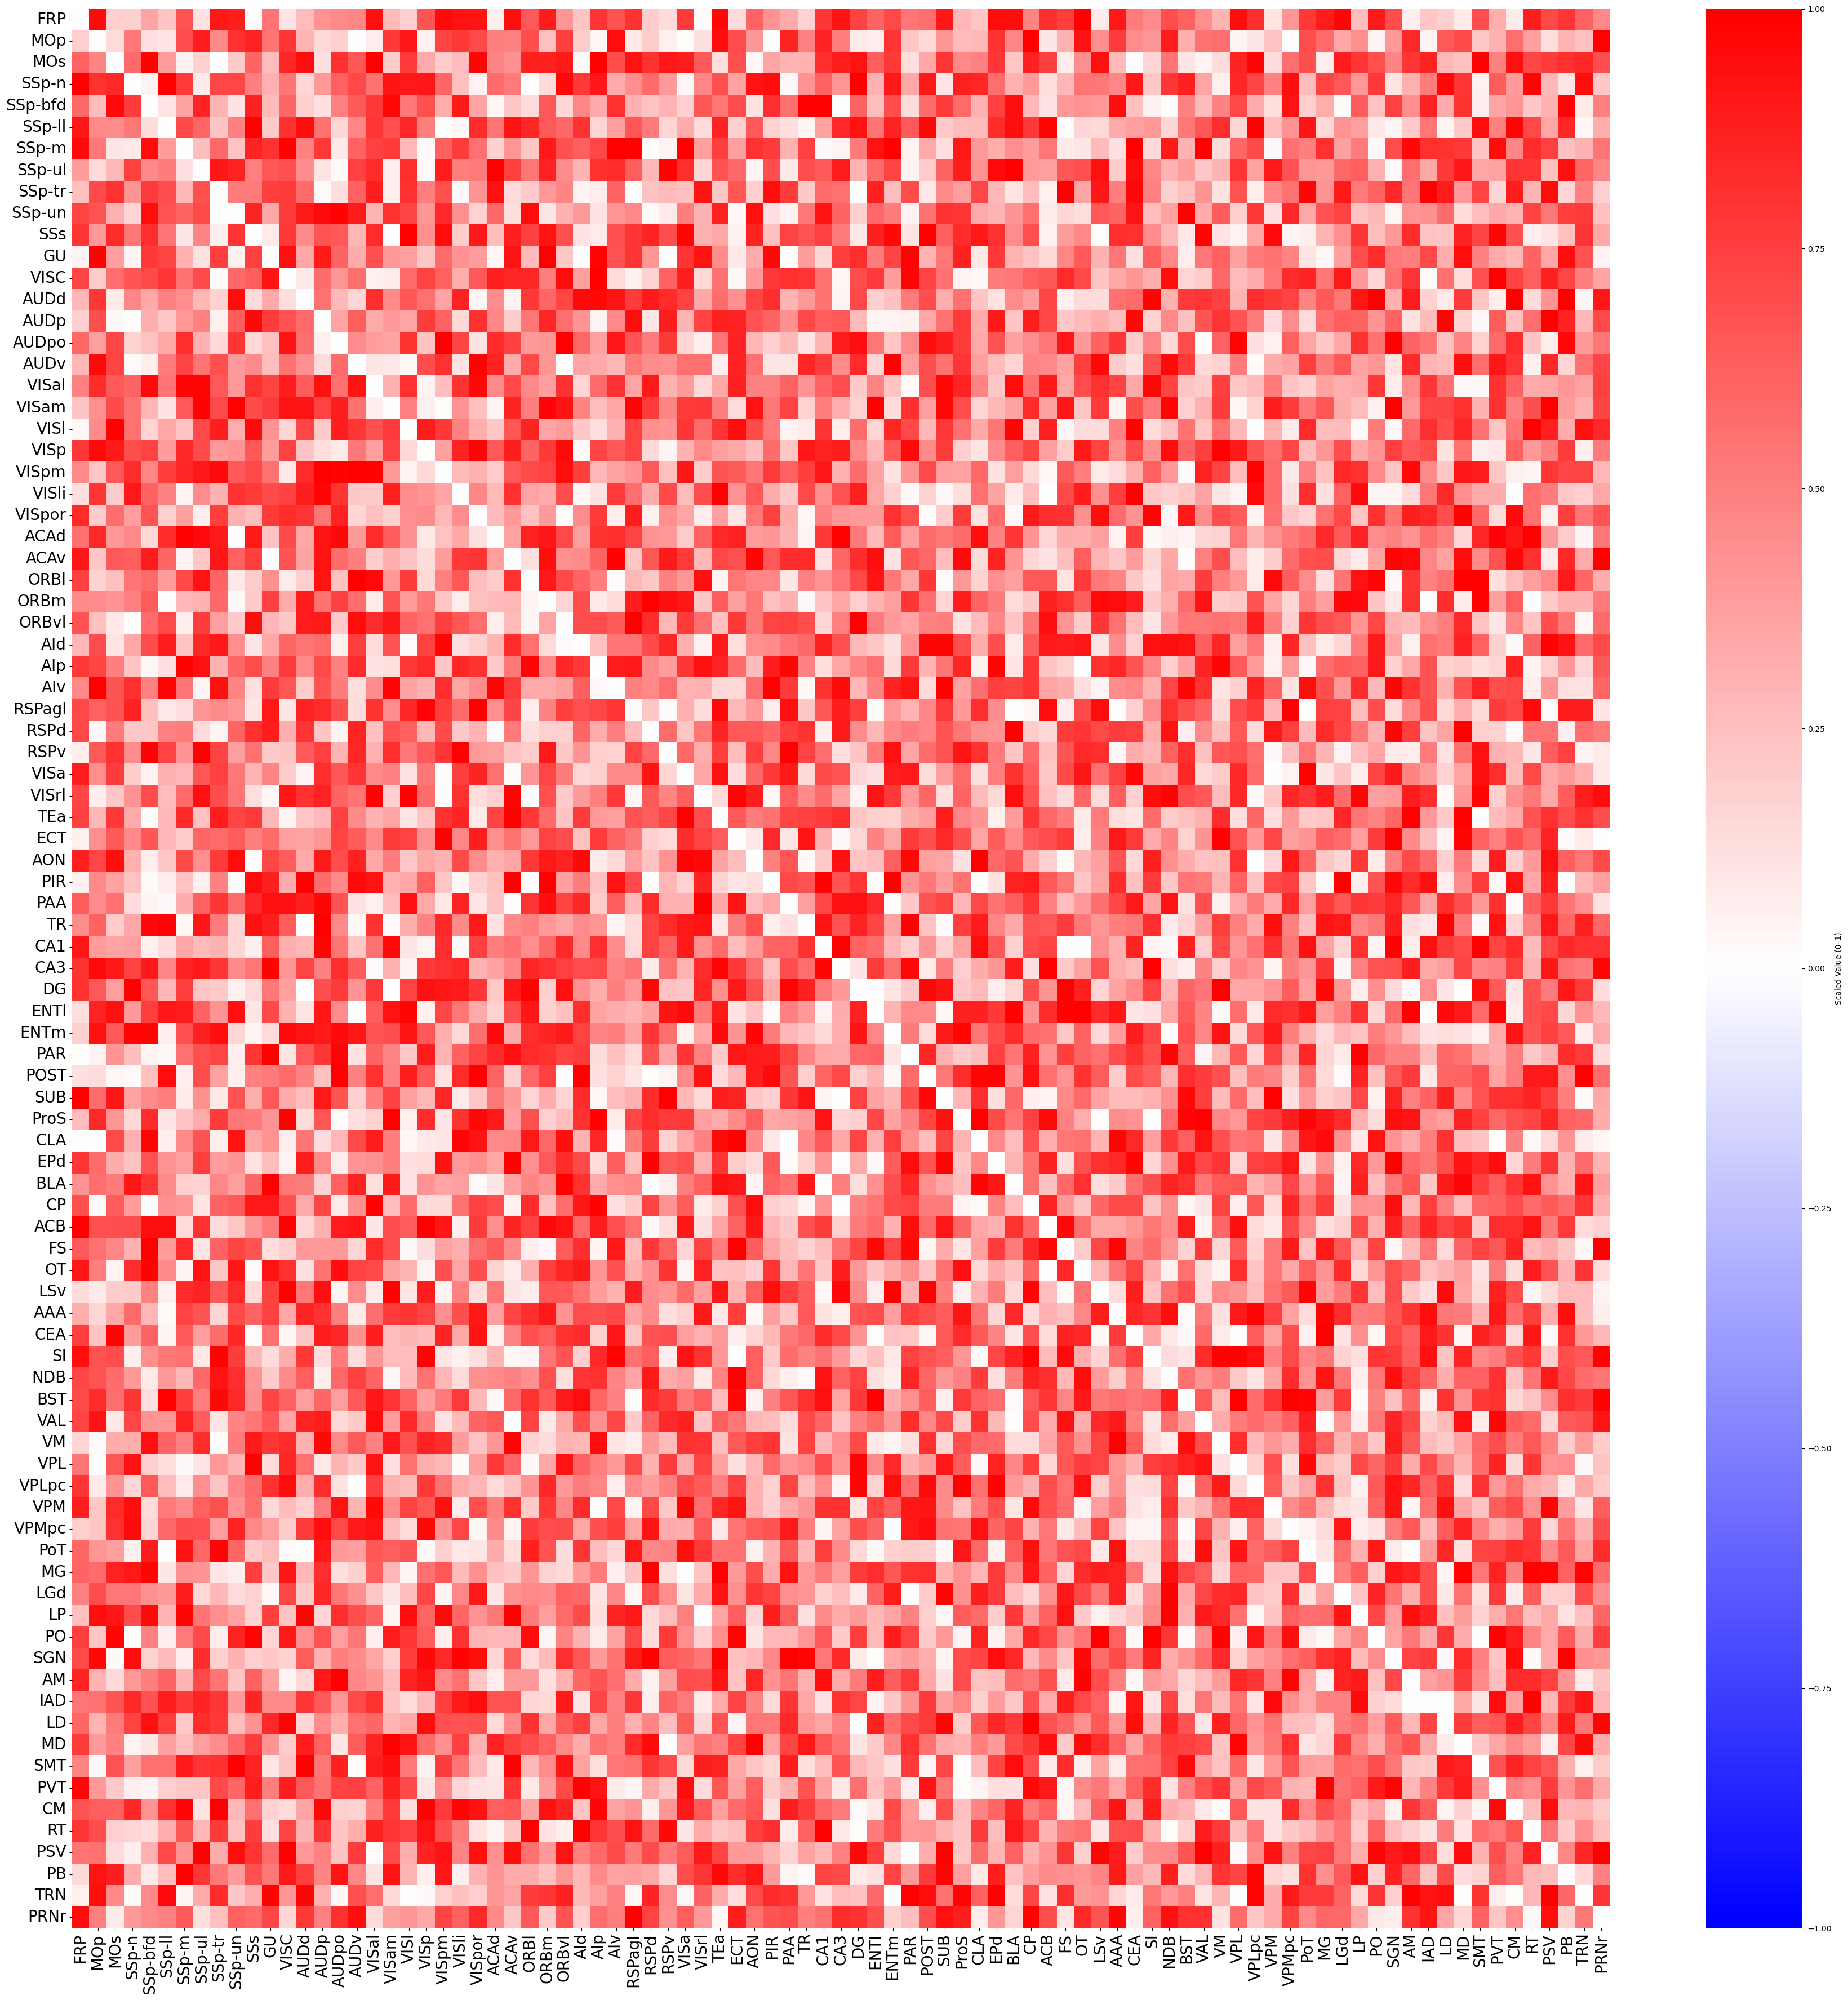

In [8]:
plt.figure(figsize=(max(10, len(df_scaled.columns) * 0.4),
                    max(8, len(df_scaled.index) * 0.4)))

ax = sns.heatmap(df_scaled, cmap='bwr', cbar_kws={'label': 'Scaled Value (0–1)'}, 
                 xticklabels=True, yticklabels=True,vmin=-1,vmax=1)

ax.set_xticks([x + 0.5 for x in range(len(df_scaled.columns))])
ax.set_xticklabels(df_scaled.columns, rotation=90, fontsize=20)

ax.set_yticks([y + 0.5 for y in range(len(df_scaled.index))])
ax.set_yticklabels(df_scaled.index, rotation=0, fontsize=20)

plt.title("", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
import numpy as np


def build_region_binned_traces_nan(
    aligned_region_data,
    dt=0.01,
    duration_mode="percentile",
    duration_percentile=100,
    convert_to_rate=False,
    rescale=True
):

    if dt <= 0:
        raise ValueError("dt must be greater than 0")

    end_times = []

    for _, data in aligned_region_data.items():

        spike_times = np.asarray(
            data.get("spike_times", []),
            dtype=float
        )

        spike_times = spike_times[
            np.isfinite(spike_times)
        ]

        if spike_times.size == 0:
            end_times.append(0.0)
        else:
            end_times.append(
                float(np.max(spike_times))
            )

    valid_end_times = np.asarray(end_times)
    valid_end_times = valid_end_times[
        valid_end_times > 0
    ]

    if valid_end_times.size == 0:
        raise ValueError(
            "No valid spike times found."
        )

    if duration_mode == "min":
        used_duration = np.min(valid_end_times)

    elif duration_mode == "median":
        used_duration = np.median(valid_end_times)

    elif duration_mode == "percentile":
        used_duration = np.percentile(
            valid_end_times,
            duration_percentile
        )

    elif duration_mode == "max":
        used_duration = np.max(valid_end_times)

    else:
        raise ValueError(
            "duration_mode must be "
            "'min', 'median', 'percentile', or 'max'"
        )

    n_bins = int(np.ceil(used_duration / dt))

    edges = np.arange(
        n_bins + 1,
        dtype=float
    ) * dt

    centers = (
        edges[:-1] +
        edges[1:]
    ) / 2

    binned = {}

    for rid, data in aligned_region_data.items():

        spike_times = np.asarray(
            data.get("spike_times", []),
            dtype=float
        )

        spike_times = spike_times[
            np.isfinite(spike_times)
        ]

        if spike_times.size == 0:

            binned[rid] = np.full(
                n_bins,
                np.nan,
                dtype=float
            )

            continue

        spike_times = spike_times[
            (spike_times >= 0) &
            (spike_times < used_duration)
        ]

        spike_counts, _ = np.histogram(
            spike_times,
            bins=edges
        )

        region_trace = spike_counts.astype(float)

        if convert_to_rate:
            region_trace /= dt

        if rescale:

            mn = region_trace.min()
            mx = region_trace.max()

            if mx > mn:
                region_trace = (
                    region_trace - mn
                ) / (mx - mn)
            else:
                region_trace = np.zeros_like(
                    region_trace,
                    dtype=float
                )

        binned[rid] = region_trace

    return centers, binned, used_duration


#################################################
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)

Automatically set line spacing: 2.20


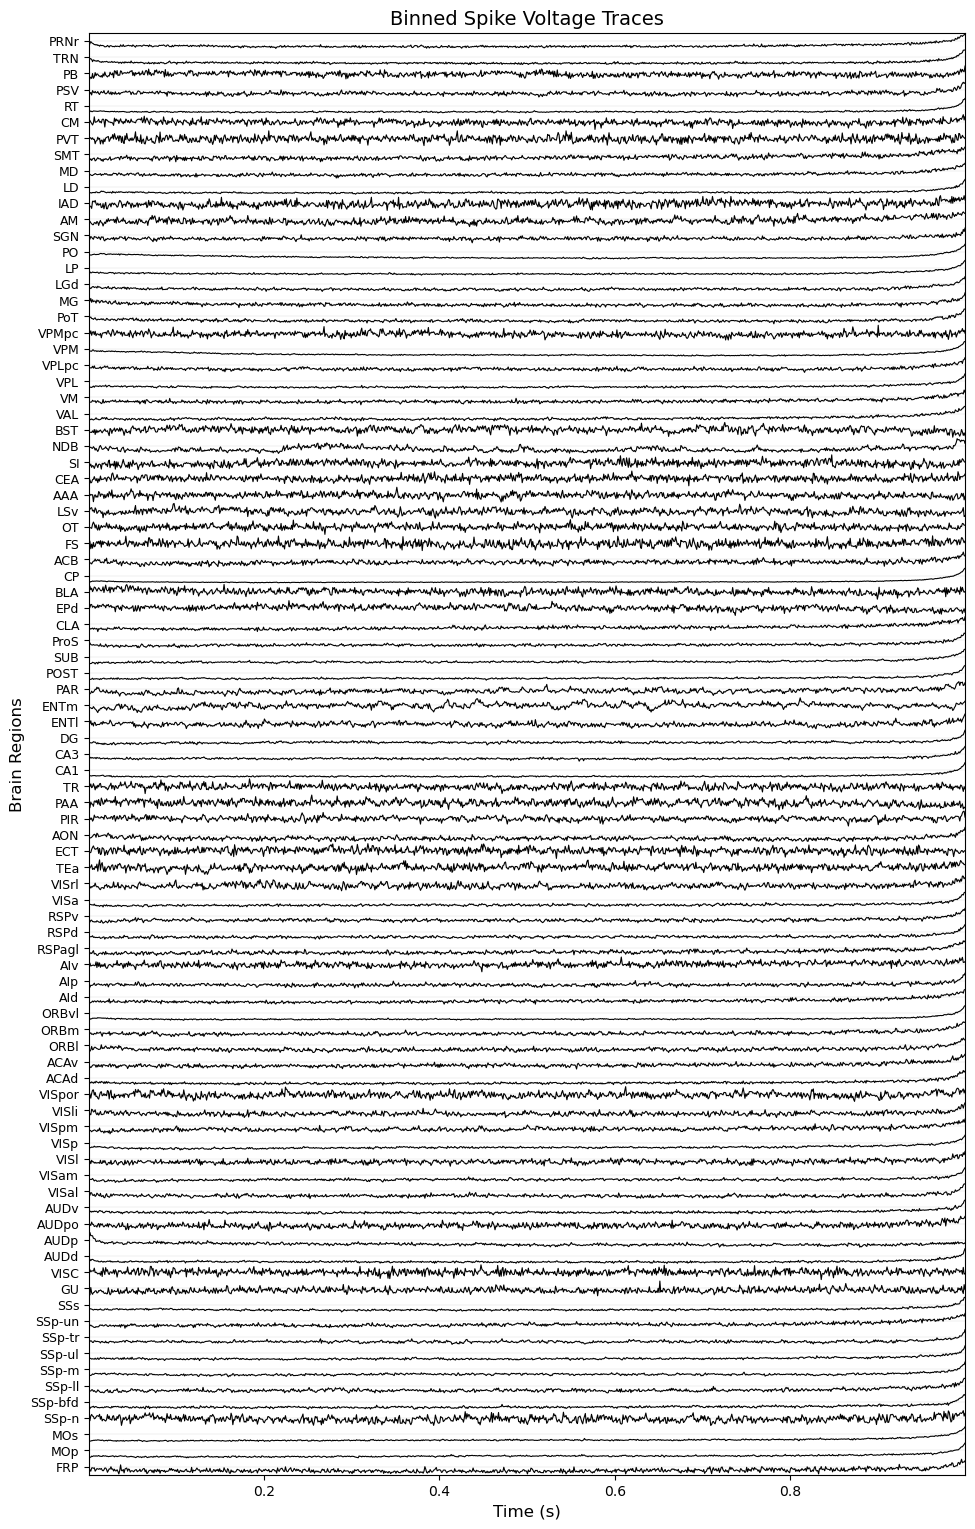

In [10]:
def plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage1",
                             auto_spacing=True, compact=True, dpi=600):

    region_names = list(binned_traces.keys())
    region_ids = region_names  

    scaled_traces = []
    max_amplitudes = []

    for name in region_names:
        trace = np.nan_to_num(binned_traces[name])
        if np.max(trace) - np.min(trace) > 0:
            trace_scaled = (trace - np.min(trace)) / (np.max(trace) - np.min(trace)) * 2 - 1
        else:
            trace_scaled = trace
        scaled_traces.append(trace_scaled)
        max_amplitudes.append(np.max(np.abs(trace_scaled)))

    if auto_spacing:
        mean_amp = np.median(max_amplitudes)
        offset_step = 2.2 * mean_amp  
    else:
        offset_step = 2.0
    print(f"Automatically set line spacing: {offset_step:.2f}")

    fig_height = max(3, len(region_names) * 0.18)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    for i, trace_scaled in enumerate(scaled_traces):
        base = i * offset_step
        ax.axhline(base, color='gray', lw=0.3, alpha=0.3)
        ax.plot(time_axis, trace_scaled + base, lw=0.8, color="black")

    ytick_positions = np.arange(0, len(region_names) * offset_step, offset_step)
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(region_names, fontsize=9)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Brain Regions", fontsize=12)
    ax.set_title("Binned Spike Voltage Traces", fontsize=14)

    if compact:
        ax.set_ylim(-offset_step * 0.5, len(region_names) * offset_step - offset_step * 0.5)
        plt.margins(x=0, y=0.01)
        plt.subplots_adjust(left=0.25, right=0.98, top=0.95, bottom=0.05)
    else:
        plt.tight_layout(pad=0.3)

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "all_trace_stage_1.png")
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()
############################################################################################
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage1")

In [11]:
# ----------------- Seed -----------------
def set_seed(seed=42):
    import random, os
    import numpy as np
    import torch

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

# ----------------- Graph-leaning -----------------
class SimpleGraphLearn(nn.Module):
    def __init__(self, node_dim, nodes, dropout=0.5, struct_connectome=None):
        super(SimpleGraphLearn, self).__init__()
        self.nodes = nodes
        self.dropout = dropout
        
        self.gate_net = nn.Sequential(
            nn.Linear(node_dim * 2, node_dim),
            nn.Sigmoid()
        )
        
        self.attention = nn.Linear(node_dim, 1, bias=False)
        self.norm = nn.LayerNorm(nodes)
        
        self.w = nn.Parameter(torch.zeros(size=(nodes, node_dim)))
        nn.init.xavier_uniform_(self.w.data, gain=1.414)
        
        if struct_connectome is not None:
            self.struct_connectome = nn.Parameter(
                torch.FloatTensor(struct_connectome), 
                requires_grad=False
            )
        else:
            self.struct_connectome = None
            
        self.graph_weight = nn.Parameter(torch.ones(1))
        self.struct_weight = nn.Parameter(torch.ones(1))
        
    def forward(self, node_features, temporal_features=None, batch_size=1):
        batch_size, nodes, node_dim = node_features.shape
        
        if temporal_features is not None:
            concat_features = torch.cat([node_features, temporal_features], dim=-1)  # (B, N, 2*D)
            gate = self.gate_net(concat_features)  # (B, N, D)
            node_features = gate * node_features + (1 - gate) * temporal_features
        
        node_res = torch.einsum('bnd, nl -> bnl', node_features, self.w) + node_features
        skip_atten = torch.einsum('bnd,bdm->bnm', node_res, node_res.transpose(-1, -2))
        skip_atten = self.norm(skip_atten)
        
        attention_scores = torch.matmul(node_features, node_features.transpose(-2, -1))  # (B, N, N)
        attention_scores = attention_scores / (node_dim ** 0.5)
        attention_scores = F.dropout(attention_scores, self.dropout, training=self.training)
        
        adj_raw = attention_scores + skip_atten
        
        if self.struct_connectome is not None:
            struct_adj = self.struct_connectome.unsqueeze(0).expand(batch_size, -1, -1)
            adj_dynamic = self.graph_weight * adj_raw + self.struct_weight * struct_adj
        else:
            adj_dynamic = adj_raw
            
        adj_dynamic = torch.tanh(adj_dynamic)
        
        if self.struct_connectome is not None:
            struct_upper_bound = self.struct_connectome.unsqueeze(0).expand(batch_size, -1, -1)
            adj_dynamic = torch.clamp(adj_dynamic, -struct_upper_bound, struct_upper_bound)
        
        return adj_dynamic

# ----------------- Temporal dynamic graph learning model -----------------
class TimeSeriesDynamicGraphModel(nn.Module):
    def __init__(self, device, num_nodes, seq_length=12, in_dim=1, out_dim=1, 
                 hidden_dim=32, dropout=0.3, embed_dim=10, heads=4, head_dim=8, 
                 struct_connectome=None):
        super(TimeSeriesDynamicGraphModel, self).__init__()
        self.device = device
        self.num_nodes = num_nodes
        self.seq_length = seq_length
        self.hidden_dim = hidden_dim
        self.dropout = dropout

        self.node_embedding = nn.Embedding(num_nodes, embed_dim)
        
        self.temporal_fusion = nn.Linear(hidden_dim, embed_dim)
        
        self.graph_learn = SimpleGraphLearn(
            node_dim=embed_dim, 
            nodes=num_nodes,
            dropout=dropout,
            struct_connectome=struct_connectome
        )

        self.temporal_encoder = nn.LSTM(
            input_size=in_dim, 
            hidden_size=hidden_dim, 
            num_layers=2, 
            batch_first=True,
            dropout=dropout
        )

        self.gcn_layers = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim) for _ in range(2)
        ])

        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, input, pred_time_embed=None):
        batch_size, seq_length, num_nodes, in_dim = input.shape
        
        idx = torch.arange(num_nodes).to(self.device)
        node_embeddings = self.node_embedding(idx)  # (num_nodes, embed_dim)
        node_embeddings = node_embeddings.unsqueeze(0).expand(batch_size, -1, -1)  # (batch_size, num_nodes, embed_dim)
        
        x_reshaped = input.permute(0, 2, 1, 3).contiguous().view(batch_size * num_nodes, seq_length, in_dim)
        temporal_out, _ = self.temporal_encoder(x_reshaped)
        
        temporal_features = temporal_out.view(batch_size, num_nodes, seq_length, -1)
        
        dynamic_graphs = []
        temporal_hiddens = []
        
        for t in range(seq_length):
            temporal_features_t = temporal_features[:, :, t, :]  # (batch_size, num_nodes, hidden_dim)
            
            temporal_features_proj_t = self.temporal_fusion(temporal_features_t)  # (batch_size, num_nodes, embed_dim)
            
            adj_dynamic_t = self.graph_learn(
                node_embeddings, 
                temporal_features_proj_t, 
                batch_size
            )  # (batch_size, num_nodes, num_nodes)
            
            dynamic_graphs.append(adj_dynamic_t)
            temporal_hiddens.append(temporal_features_t)
        
        adj_dynamic_all = torch.stack(dynamic_graphs, dim=1)  # (batch_size, seq_length, num_nodes, num_nodes)
        
        gcn_outputs_all = []
        
        for t in range(seq_length):
            h_t = temporal_hiddens[t]  # (batch_size, num_nodes, hidden_dim)
            adj_t = dynamic_graphs[t]  # (batch_size, num_nodes, num_nodes)
            
            gcn_outputs_t = []
            current_h = h_t
            for gcn_layer in self.gcn_layers:
                h_gcn = torch.matmul(adj_t.transpose(-1, -2), current_h)  
                h_gcn = gcn_layer(h_gcn)
                h_gcn = F.relu(h_gcn)
                h_gcn = F.dropout(h_gcn, self.dropout, training=self.training)
                gcn_outputs_t.append(h_gcn)
                current_h = h_gcn
            
            gcn_outputs_all.append(current_h)
        
        gcn_outputs_all = torch.stack(gcn_outputs_all, dim=1)  # (batch_size, seq_length, num_nodes, hidden_dim)
        
        final_hidden = gcn_outputs_all[:, -1, :, :]  # (batch_size, num_nodes, hidden_dim)
        output = self.output_layer(final_hidden)  # (batch_size, num_nodes, out_dim)
        
        return output, None, adj_dynamic_all

# ----------------- Trainer -----------------
class trainer():
    def __init__(self, num_nodes, seq_length, in_dim, out_dim, hidden_dim, dropout, lrate, wdecay, device, 
                 embed_dim, heads=4, head_dim=8, struct_connectome=None, struct_constraint_weight=0.2):
        
        self.model = TimeSeriesDynamicGraphModel(
            device, num_nodes, seq_length, in_dim, out_dim,
            hidden_dim=hidden_dim, dropout=dropout, embed_dim=embed_dim,
            heads=heads, head_dim=head_dim, struct_connectome=struct_connectome
        )
        
        self.model.to(device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=lrate, weight_decay=wdecay)
        self.scheduler = lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10, eps=0.00001, cooldown=20, verbose=True
        )
        
        self.loss = nn.MSELoss()
        self.clip = 0.5
        self.struct_constraint_weight = struct_constraint_weight

    def train(self, input, real_val, iter=0):
        self.model.train()
        output, gl_loss, adj_d = self.model(input)
        
        loss = self.loss(output, real_val)
        
        if hasattr(self.model.graph_learn, 'struct_connectome') and \
           self.model.graph_learn.struct_connectome is not None:
            
            # adj_d (batch_size, seq_length, num_nodes, num_nodes)
            if len(adj_d.shape) == 4:  # (batch_size, seq_length, num_nodes, num_nodes)
                avg_adj = torch.mean(adj_d, dim=(0, 1))  
            elif len(adj_d.shape) == 3:  # (batch_size, num_nodes, num_nodes)
                avg_adj = torch.mean(adj_d, dim=0)
            else:
                avg_adj = adj_d
            
            struct_adj = self.model.graph_learn.struct_connectome
            
            avg_adj_abs = torch.abs(avg_adj)
            struct_loss = F.mse_loss(avg_adj_abs, struct_adj)
            
            loss = loss + self.struct_constraint_weight * struct_loss
        
        loss.backward()
        
        if self.clip is not None:
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.clip)
        
        self.optimizer.step()
        self.optimizer.zero_grad()
        
        return loss.item()

    def eval(self, input, real_val):
        self.model.eval()
        with torch.no_grad():
            output, gl_loss, adj_d = self.model(input)
            loss = self.loss(output, real_val)
        return loss.item(), output, adj_d

# ----------------- Main training function -----------------
def train_timeseries_dynamic_graph(
    cell_trace, struct_connectome, seq_length, pred_length,
    hidden_dim, lr, epochs, batch_size, dropout,
    device=None, seed=42, val_ratio=0.2, patience=20,
    heads=4, head_dim=8, embed_dim=10, struct_constraint_weight=0.5,
    save_dir="./results/wo_layer/stage1"   
):

    import os, numpy as np, torch, random
    from tqdm import tqdm

    set_seed(seed)
    # Create save folder
    os.makedirs(save_dir, exist_ok=True)

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    #torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)

    num_regions, total_time = cell_trace.shape
    if seq_length is None:
        seq_length = total_time - pred_length

    # ------------------ Data input ------------------
    data, targets = [], []
    cell_trace = (cell_trace - np.mean(cell_trace)) / (np.std(cell_trace) + 1e-8)

    for t in range(total_time - seq_length - pred_length + 1):
        x = cell_trace[:, t:t+seq_length].T.reshape(seq_length, num_regions, 1)
        y = cell_trace[:, t+seq_length:t+seq_length+pred_length].T.reshape(num_regions, pred_length)
        data.append(x); targets.append(y)

    data, targets = np.array(data), np.array(targets)
    split = int(len(data) * (1 - val_ratio))

    train_data = torch.FloatTensor(data[:split]).to(device)
    train_targets = torch.FloatTensor(targets[:split]).to(device)
    val_data = torch.FloatTensor(data[split:]).to(device)
    val_targets = torch.FloatTensor(targets[split:]).to(device)

    # ------------------ Model ------------------
    engine = trainer(
        num_nodes=num_regions, seq_length=seq_length, in_dim=1, out_dim=pred_length,
        hidden_dim=hidden_dim, dropout=dropout, lrate=lr, wdecay=0.0, device=device,
        embed_dim=embed_dim, heads=heads, head_dim=head_dim,
        struct_connectome=struct_connectome, struct_constraint_weight=struct_constraint_weight
    )

    best_val = float('inf'); patience_count = 0
    train_losses, val_losses = [], []
    epoch_avg_graphs = []

    print(f"Training start | seq={seq_length}, T={total_time}")

    # ------------------ Train ------------------
    for epoch in range(epochs):
        engine.model.train()
        train_loss = 0
        for i in range(0, len(train_data), batch_size):
            train_loss += engine.train(train_data[i:i+batch_size], train_targets[i:i+batch_size])
        train_loss /= (len(train_data)//batch_size + 1)
        train_losses.append(train_loss)

        # -------- Validation --------
        engine.model.eval()
        val_loss = 0
        with torch.no_grad():
            for i in range(0, len(val_data), batch_size):
                val_loss += engine.eval(val_data[i:i+batch_size], val_targets[i:i+batch_size])[0]
        val_loss /= (len(val_data)//batch_size + 1)
        val_losses.append(val_loss)
        engine.scheduler.step(val_loss)

        # ---- Save best ----
        if val_loss < best_val:
            best_val = val_loss
            patience_count = 0
            torch.save(engine.model.state_dict(), f"{save_dir}/best_model.pth")  
        else:
            patience_count += 1
        if patience_count >= patience:
            print(f"Early stop @ epoch {epoch+1}")
            break

        # ---- collect epoch avg graph ----
        with torch.no_grad():
            x = train_data[0:1]
            _, _, adj = engine.model(x)
            epoch_avg_graphs.append(np.mean(adj.squeeze(0).cpu().numpy(), axis=0))

        if (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train {train_loss:.5f} | Val {val_loss:.5f}")

    print("Training done, loading best model")
    engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))
    engine.model.eval()

    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))
    np.save(f"{save_dir}/epoch_avg_graphs.npy", np.array(epoch_avg_graphs))
    print(f"Saved epoch_avg_graphs.npy to {save_dir}")

    # ------------------ Full time inference ------------------
    print("Reconstructing full dynamic graph...")

    full_dynamic_graphs = np.zeros((total_time, num_regions, num_regions))
    frame_count = np.zeros(total_time)

    with torch.no_grad():
        for t in tqdm(range(total_time - seq_length + 1)):
            x = cell_trace[:, t:t+seq_length].T.reshape(1, seq_length, num_regions, 1)
            x = torch.FloatTensor(x).to(device)

            _, _, adj_seq = engine.model(x)
            adj_seq = adj_seq.squeeze(0).cpu().numpy()

            for k in range(seq_length):
                idx = t + k
                full_dynamic_graphs[idx] += adj_seq[k]
                frame_count[idx] += 1

    for i in range(total_time):
        if frame_count[i] > 0:
            full_dynamic_graphs[i] /= frame_count[i]

    np.save(f"{save_dir}/dynamic_full_graphs.npy", full_dynamic_graphs)
    print(f"Saved dynamic_full_graphs.npy to {save_dir}, shape={full_dynamic_graphs.shape}")

    return engine.model, train_losses, val_losses, full_dynamic_graphs

In [12]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in binned_traces.keys()])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

batch_sizes = [32]
dropouts = [0.1]
struct_weights = [1.0]

for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):

    save_dir = f"./result/wo_layer/stage1/tuning/bs{bs}_dp{dp}_sw{sw}_seed{seed}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )

    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

Training with batch_size=32, dropout=0.1, struct_constraint_weight=1.0
Save dir: ./result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0_seed12


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Training start | seq=50, T=1000
Epoch 20/300 | Train 0.62907 | Val 0.90775
Epoch 40/300 | Train 0.54228 | Val 0.88391
Epoch 60/300 | Train 0.50403 | Val 0.87280
Epoch 80/300 | Train 0.48465 | Val 0.89501


/tmp/ipykernel_1211665/3657165358.py:334: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 82
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0_seed12
Reconstructing full dynamic graph...


100%|██████████| 951/951 [00:25<00:00, 37.20it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0_seed12, shape=(1000, 89, 89)
Finished: bs=32 dp=0.1 sw=1.0 | Saved to ./result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0_seed12


## 2. Stage2

In [13]:
with open('../../brain_region_wo_layer_stage2.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([1.32295741e-06, 2.22448016e-06, 4.46894026e-06, ...,
         9.99998459e-01, 9.99998823e-01, 1.00000000e+00]),
  'spike_voltages': array([1.02225975e-04, 1.90227904e-04, 6.86466592e-05, ...,
         1.46565464e-04, 1.36938193e-04, 8.16656393e-05])},
 'LGd': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([1.15912066e-04, 2.21375594e-04, 2.84903537e-04, ...,
         7.53099230e-05, 1.34822039e-04, 6.84298866e-05])},
 'CEA': {'spike_times': array([9.88512933e-07, 3.90553693e-06, 7.73567368e-06, ...,
         9.99995064e-01, 9.99997947e-01, 9.99999048e-01]),
  'spike_voltages': array([2.71024008e-04, 1.77588983e-04, 8.60513755e-05, ...,
         1.29396503e-04, 9.81526682e-05, 5.01546710e-05])},
 'VPM': {'spike_times': array([4.29821969e-10, 5.48716916e-10, 1.60778299e-09, ...,
         1.00000000e+00, 1.00000000e+00, 1.00000000e+00]),
  'spike_voltages': array([0.00018025, 0.00016094, 0.00014604, ..., 0.00022785, 0.00015073

Automatically set line spacing: 2.20


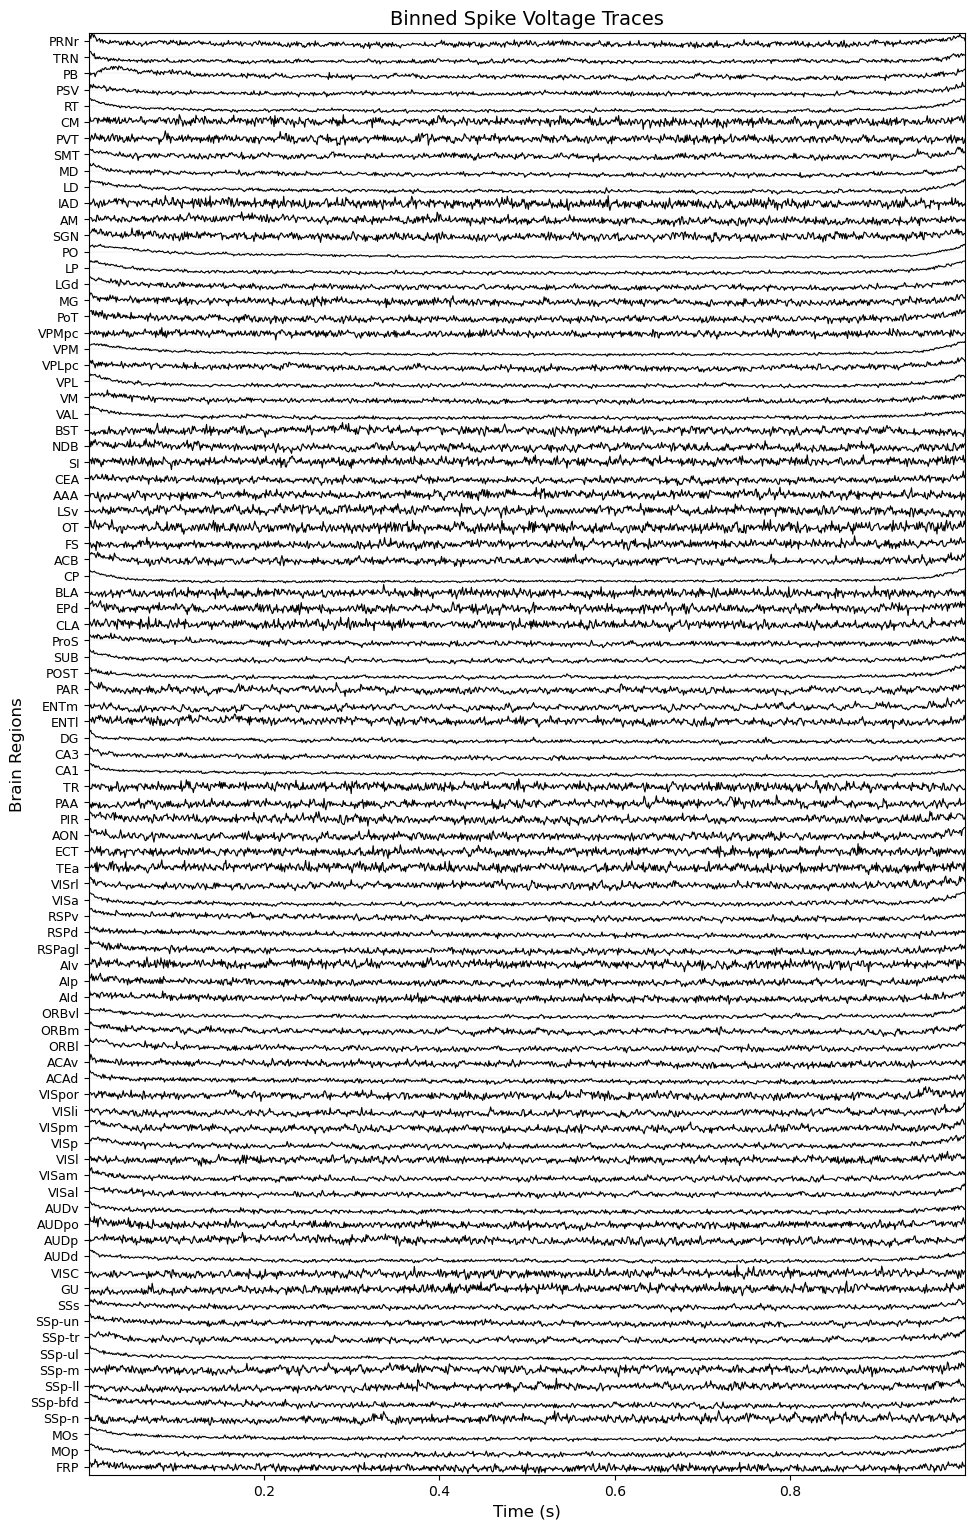

In [14]:
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage2")

In [15]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in binned_traces.keys()])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

batch_sizes = [32]
dropouts = [0.1]
struct_weights = [1.0]

for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):


    save_dir = f"./result/wo_layer/stage2/tuning/bs{bs}_dp{dp}_sw{sw}_seed{seed}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )


    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

Training with batch_size=32, dropout=0.1, struct_constraint_weight=1.0
Save dir: ./result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0_seed12
Training start | seq=50, T=1000


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 20/300 | Train 0.78211 | Val 0.84332
Epoch 40/300 | Train 0.71308 | Val 0.77866
Epoch 60/300 | Train 0.67277 | Val 0.77403
Epoch 80/300 | Train 0.65037 | Val 0.76215


/tmp/ipykernel_1211665/3657165358.py:334: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 89
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0_seed12
Reconstructing full dynamic graph...


100%|██████████| 951/951 [00:25<00:00, 36.88it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0_seed12, shape=(1000, 89, 89)
Finished: bs=32 dp=0.1 sw=1.0 | Saved to ./result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0_seed12


## 3. Stage3

In [16]:
with open('../../brain_region_wo_layer_stage3.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999878, 0.99999891,
         0.99999918]),
  'spike_voltages': array([9.83134669e-05, 1.10490560e-04, 1.20823541e-04, ...,
         8.66546034e-05, 2.00705254e-04, 1.16139279e-04])},
 'LGd': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999913, 0.99999964,
         0.9999999 ]),
  'spike_voltages': array([0.00015002, 0.00029779, 0.00034073, ..., 0.00015605, 0.00034507,
         0.00027978])},
 'CEA': {'spike_times': array([1.73867369e-06, 1.78239708e-06, 2.93794786e-06, ...,
         9.99996203e-01, 9.99997407e-01, 9.99997555e-01]),
  'spike_voltages': array([1.17482829e-04, 1.79528535e-04, 1.30806802e-04, ...,
         8.07435208e-05, 1.05170860e-04, 6.93560651e-05])},
 'VPM': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999934, 0.99999982,
         0.99999985]),
  'spike_voltages': array([0.00020572, 0.00025564, 0.00011258, ..., 0.00017012, 0.00011777,
         0.00

Automatically set line spacing: 2.20


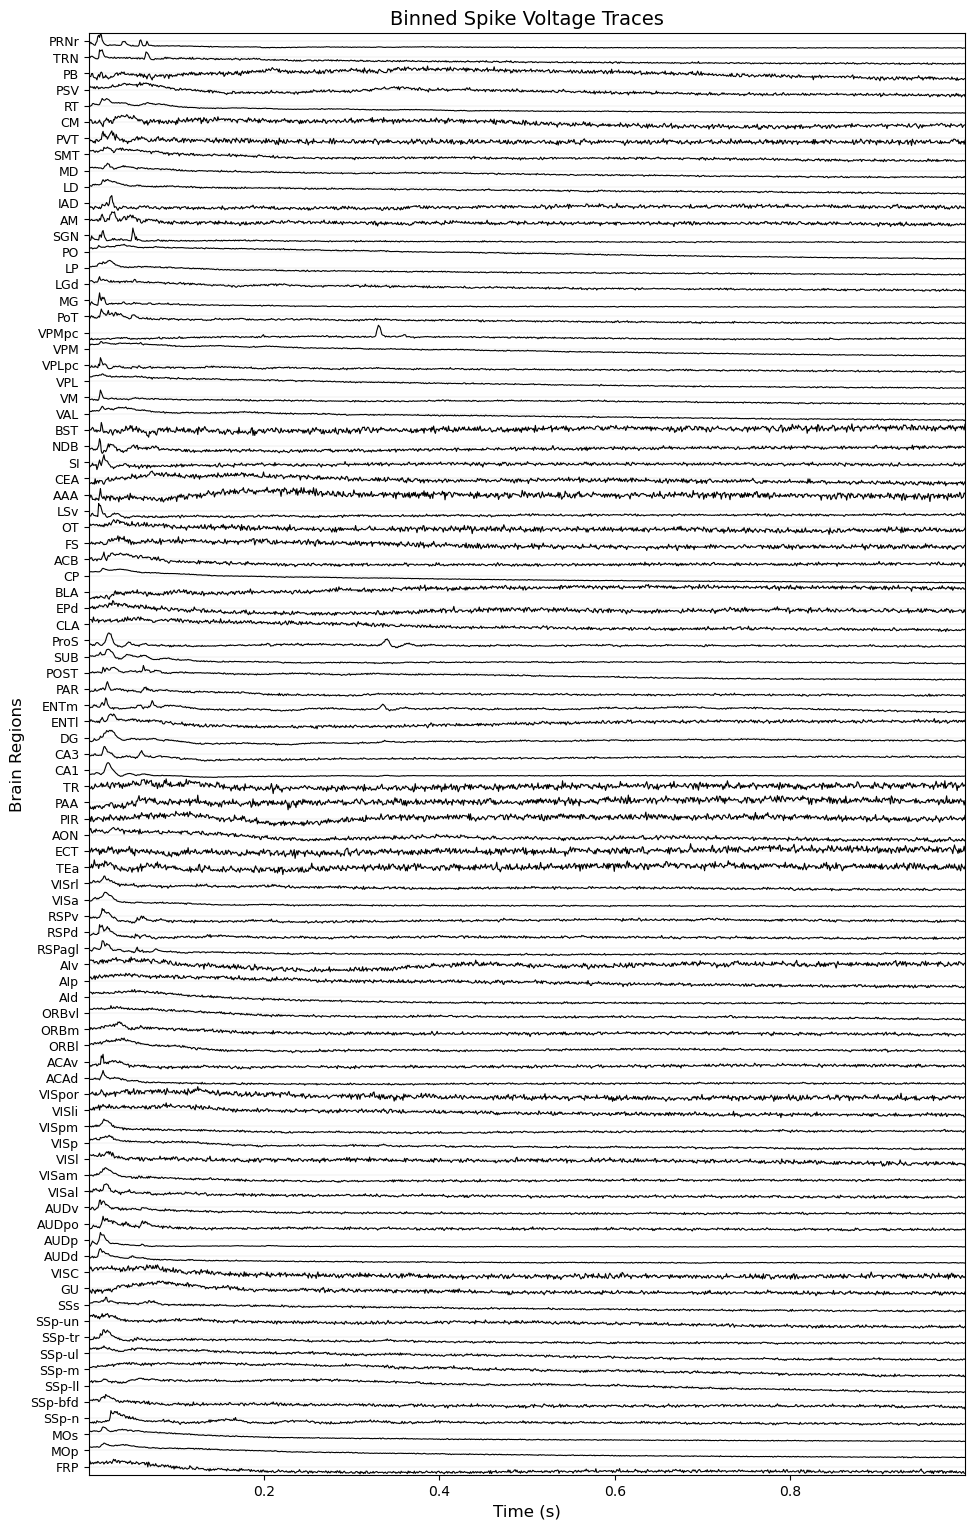

In [17]:
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage3")

In [18]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in binned_traces.keys()])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

batch_sizes = [32]
dropouts = [0.1]
struct_weights = [0.5]

for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):

    save_dir = f"./result/wo_layer/stage3/tuning/bs{bs}_dp{dp}_sw{sw}_seed{seed}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )

    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

Training with batch_size=32, dropout=0.1, struct_constraint_weight=0.5
Save dir: ./result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5_seed12
Training start | seq=50, T=1000


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 20/300 | Train 0.62851 | Val 0.47455
Epoch 40/300 | Train 0.53647 | Val 0.36819
Epoch 60/300 | Train 0.48685 | Val 0.35666
Epoch 80/300 | Train 0.44742 | Val 0.31328
Epoch 100/300 | Train 0.43740 | Val 0.30356
Epoch 120/300 | Train 0.41079 | Val 0.29538
Epoch 140/300 | Train 0.40021 | Val 0.28199
Epoch 160/300 | Train 0.38618 | Val 0.27123
Epoch 180/300 | Train 0.37632 | Val 0.28325


/tmp/ipykernel_1211665/3657165358.py:334: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 181
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5_seed12
Reconstructing full dynamic graph...


100%|██████████| 951/951 [00:26<00:00, 35.95it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5_seed12, shape=(1000, 89, 89)
Finished: bs=32 dp=0.1 sw=0.5 | Saved to ./result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5_seed12
